# ESE 5420 Baseline — L2 Logistic Regression on Feature Sets S1–S6

End-to-end baseline checkpoint for the Online Shoppers Purchasing Intention project.

**Pipeline overview**

1. Load the UCI dataset (12,330 sessions, 17 predictors, binary target `Revenue`).
2. Stratified 20% test set with a fixed seed; only touched for the final held-out score.
3. Define the five hand-designed feature sets **S1–S5** following `01_preprocessing_eda_selection.ipynb` Phase 5, and reproduce Phase 6 forward feature selection (now driven by L2 Logistic Regression) to produce **S6**.
4. For each of S1–S6, tune the L2 strength `C` of `LogisticRegression(solver="lbfgs")` on a log-spaced grid by stratified 5-fold CV; preprocessing is refit inside every fold.
5. Fit the best-`C` model per set on the full training set; score Test AP with a 1,000-sample bootstrap 95% CI.
6. Primary baseline reported in `baseline.txt` is **S3** (session + browsing, 16 features, PageValues excluded). PageValues is UCI-defined from sessions that ended in a transaction, so **S4** (with PageValues) is reported only as the leakage comparator.

## 0. Imports, random seed, and workarounds

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn import set_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from ucimlrepo import fetch_ucirepo

# Global random state used for every seeded step (split, CV shuffle, bootstrap).
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Avoid GBK codec error on Chinese Windows + Python 3.14 + sklearn >= 1.8
# (sklearn's HTML-diagram repr tries to open estimator.js without encoding="utf-8").
set_config(display="text")

# Additional defensive workaround: monkey-patch open() inside sklearn's HTML repr
# module to force UTF-8 for .js/.html/.css reads. This covers the _repr_html_inner
# path that bypasses set_config and would still trigger the GBK error otherwise.
import sklearn.utils._repr_html.estimator as _skl_est
import builtins as _builtins
_original_open = _builtins.open
def _utf8_open(*args, **kwargs):
    if args and isinstance(args[0], (str, Path)) and str(args[0]).endswith((".js", ".html", ".css")):
        kwargs.setdefault("encoding", "utf-8")
    return _original_open(*args, **kwargs)
_skl_est.open = _utf8_open

## 1. Data loading

Fetch the dataset directly from the UCI ML repository (ID 468) and verify the documented 12,330 sessions and the ~15.5% purchase rate.

In [2]:
dataset = fetch_ucirepo(id=468)
X_raw = dataset.data.features
y_raw = dataset.data.targets
df = pd.concat([X_raw, y_raw], axis=1)
if "Revenue" not in df.columns:
    df = df.rename(columns={df.columns[-1]: "Revenue"})
df["Revenue"] = df["Revenue"].astype(bool)

overview = pd.DataFrame({
    "Quantity": ["# Sessions", "# Predictors", "Positive rate (Revenue=True)"],
    "Value":    [len(df), df.shape[1] - 1, round(float(df["Revenue"].mean()), 4)]
})
print(overview.to_string(index=False))

                    Quantity      Value
                  # Sessions 12330.0000
                # Predictors    17.0000
Positive rate (Revenue=True)     0.1547


## 2. Train/Test split

Stratified 80/20 split with `random_state=42`. `StratifiedGroupKFold` is keyed on the full predictor pattern so that the 125 exact duplicate rows cannot straddle train and test. The test set is set aside and only used in Section 8 for the final held-out score.

In [3]:
X = df.drop(columns=["Revenue"])
y = df["Revenue"]

group_ids = pd.factorize(pd.MultiIndex.from_frame(X), sort=False)[0]

initial_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(initial_splitter.split(X, y, groups=group_ids))

X_train = X.iloc[train_idx].copy()
X_test  = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test  = y.iloc[test_idx].copy()
group_ids_train = group_ids[train_idx]

y_train_int = y_train.astype(int)
y_test_int  = y_test.astype(int)

split_summary = pd.DataFrame({
    "Set": ["Training", "Test"],
    "N":   [len(y_train_int), len(y_test_int)],
    "Share of dataset": [round(len(y_train_int)/len(df), 3),
                         round(len(y_test_int)/len(df), 3)],
    "Positive rate":    [round(float(y_train_int.mean()), 4),
                         round(float(y_test_int.mean()),  4)]
})
print(split_summary.to_string(index=False))

     Set    N  Share of dataset  Positive rate
Training 9864               0.8         0.1547
    Test 2466               0.2         0.1549


## 3. Feature sets S1–S5 (hand-designed)

The five hand-designed feature sets from Phase 5 of `01_preprocessing_eda_selection.ipynb`:

| Set | Features | Count | Purpose |
|---|---|---|---|
| **S1** | Session context only | 8 | `VisitorType`, `Month`, `Weekend`, `SpecialDay`, `OperatingSystems`, `Browser`, `Region`, `TrafficType` |
| **S2** | Browsing behavior only | 8 | `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `BounceRates`, `ExitRates` |
| **S3** | S1 ∪ S2 | 16 | Complete baseline **excluding PageValues** (leakage-free) — **primary baseline** |
| **S4** | S3 ∪ {PageValues} | 17 | All original predictors (**with-PageValues leakage comparator**) |
| **S5** | S2 ∪ {PageValues} | 9 | Browsing behavior + PageValues (no session context) |

The S6 set is produced by forward selection in Section 4.

In [4]:
# ----- Feature-set definitions (copied from 01 Phase 5) -----
session_context_features = [
    "VisitorType", "Month", "Weekend", "SpecialDay",
    "OperatingSystems", "Browser", "Region", "TrafficType"
]
browsing_behavior_features = [
    "Administrative", "Administrative_Duration",
    "Informational",  "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates",    "ExitRates"
]

feature_sets = {
    "S1": list(session_context_features),
    "S2": list(browsing_behavior_features),
    "S3": list(session_context_features) + list(browsing_behavior_features),
    "S4": list(X_train.columns),
    "S5": list(browsing_behavior_features) + ["PageValues"],
}

feature_set_purposes = {
    "S1": "Session context only",
    "S2": "Browsing behavior only",
    "S3": "Complete baseline excluding PageValues (PRIMARY)",
    "S4": "All original predictors (with PageValues - leakage comparator)",
    "S5": "Browsing behavior with PageValues",
}

# Sanity checks match 01 Phase 5.
expected_feature_counts = {"S1": 8, "S2": 8, "S3": 16, "S4": 17, "S5": 9}
for s_name, features in feature_sets.items():
    assert len(features) == expected_feature_counts[s_name], s_name
    assert len(features) == len(set(features)), s_name
    assert set(features).issubset(X_train.columns), s_name
    assert "Revenue" not in features, s_name
assert "PageValues" not in feature_sets["S3"]
assert "PageValues" in feature_sets["S4"] and "PageValues" in feature_sets["S5"]

# ----- Preprocessor factory (used in every CV fold refit) -----
numerical_features = [
    "Administrative", "Administrative_Duration",
    "Informational",  "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates",    "ExitRates", "PageValues", "SpecialDay"
]
categorical_features = ["OperatingSystems", "Browser", "Region", "TrafficType",
                        "Month", "VisitorType"]
boolean_features = ["Weekend"]


def build_preprocessor(features):
    # Column-aware preprocessor for one feature subset.
    sel_num  = [f for f in numerical_features   if f in features]
    sel_cat  = [f for f in categorical_features if f in features]
    sel_bool = [f for f in boolean_features     if f in features]
    transformers = []
    if sel_num:  transformers.append(("numeric",     StandardScaler(),                       sel_num))
    if sel_cat:  transformers.append(("categorical", OneHotEncoder(handle_unknown="ignore"), sel_cat))
    if sel_bool: transformers.append(("boolean",     "passthrough",                          sel_bool))
    return ColumnTransformer(transformers=transformers, remainder="drop",
                             verbose_feature_names_out=False)


feature_set_summary = pd.DataFrame([{
    "Feature Set":          s_name,
    "# Features":           len(features),
    "Includes PageValues":  "PageValues" in features,
    "Purpose":              feature_set_purposes[s_name]
} for s_name, features in feature_sets.items()])
print(feature_set_summary.to_string(index=False))

Feature Set  # Features  Includes PageValues                                                        Purpose
         S1           8                False                                           Session context only
         S2           8                False                                         Browsing behavior only
         S3          16                False               Complete baseline excluding PageValues (PRIMARY)
         S4          17                 True All original predictors (with PageValues - leakage comparator)
         S5           9                 True                              Browsing behavior with PageValues


## 4. Forward Feature Selection — produce S6

Reproduce Phase 6 of `01_preprocessing_eda_selection.ipynb`, but with the primary classifier (L2 Logistic Regression at C=1.0) replacing Ridge regression as the scorer. The candidate pool is **S3** (16 features, no PageValues). Average Precision is the scoring metric, evaluated by the same 5-fold `StratifiedGroupKFold`.

At each step we greedily add the feature whose inclusion maximizes Mean CV AP. After traversing the full 16-step path, **S6** is defined as the smallest prefix whose Mean CV AP is within `0.001` of the overall maximum (the parsimony rule).

**Expected runtime: ~10–15 minutes** (680 LogReg fits).

[ 1/16] + ExitRates                     Mean CV AP = 0.2646  SD = 0.0164
[ 2/16] + Month                         Mean CV AP = 0.3122  SD = 0.0095
[ 3/16] + ProductRelated_Duration       Mean CV AP = 0.3304  SD = 0.0049
[ 4/16] + OperatingSystems              Mean CV AP = 0.3348  SD = 0.0096
[ 5/16] + SpecialDay                    Mean CV AP = 0.3352  SD = 0.0090
[ 6/16] + VisitorType                   Mean CV AP = 0.3350  SD = 0.0149
[ 7/16] + TrafficType                   Mean CV AP = 0.3348  SD = 0.0179
[ 8/16] + BounceRates                   Mean CV AP = 0.3350  SD = 0.0166
[ 9/16] + Weekend                       Mean CV AP = 0.3352  SD = 0.0167
[10/16] + Browser                       Mean CV AP = 0.3345  SD = 0.0175
[11/16] + Region                        Mean CV AP = 0.3348  SD = 0.0193
[12/16] + Administrative                Mean CV AP = 0.3333  SD = 0.0186
[13/16] + Administrative_Duration       Mean CV AP = 0.3327  SD = 0.0195
[14/16] + ProductRelated                Mean CV AP 

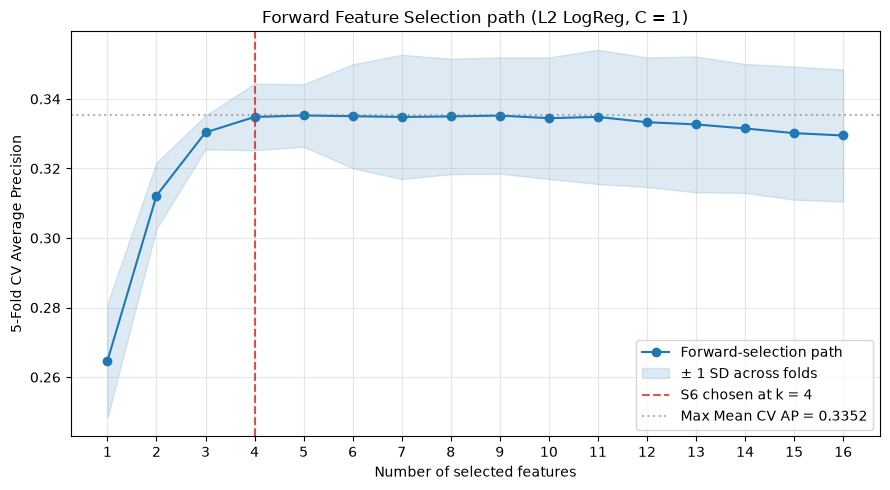

In [5]:
FORWARD_SELECTION_C = 1.0
SELECTION_TOLERANCE = 1e-3

forward_selection_candidates = list(feature_sets["S3"])
assert "PageValues" not in forward_selection_candidates
assert len(forward_selection_candidates) == 16

forward_selection_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def compute_cv_ap_logreg(feature_subset, C_value):
    # Return (mean, std) 5-fold CV Average Precision for one (features, C) pair.
    fold_scores = []
    for fold_tr_idx, fold_va_idx in forward_selection_cv.split(
        X_train, y_train_int, groups=group_ids_train
    ):
        pipeline = Pipeline([
            ("preprocessor", build_preprocessor(feature_subset)),
            ("model", LogisticRegression(
                solver="lbfgs", C=C_value, max_iter=5000, random_state=RANDOM_STATE
            ))
        ])
        pipeline.fit(X_train.iloc[fold_tr_idx], y_train_int.iloc[fold_tr_idx])
        y_va_score = pipeline.predict_proba(X_train.iloc[fold_va_idx])[:, 1]
        fold_scores.append(
            average_precision_score(y_train_int.iloc[fold_va_idx], y_va_score)
        )
    return float(np.mean(fold_scores)), float(np.std(fold_scores))


selected_features  = []
remaining_features = list(forward_selection_candidates)
selection_history  = []

while remaining_features:
    step_scores = []
    for candidate in remaining_features:
        trial_subset = selected_features + [candidate]
        trial_mean, trial_std = compute_cv_ap_logreg(trial_subset, FORWARD_SELECTION_C)
        step_scores.append((candidate, trial_mean, trial_std))
    step_scores.sort(key=lambda t: t[1], reverse=True)
    best_feat, best_mean, best_std = step_scores[0]
    selected_features.append(best_feat)
    remaining_features.remove(best_feat)
    selection_history.append({
        "Step":           len(selected_features),
        "Added Feature":  best_feat,
        "Features So Far":len(selected_features),
        "Mean CV AP":     best_mean,
        "Std CV AP":      best_std,
    })
    print(f"[{len(selected_features):2d}/16] + {best_feat:28s}  "
          f"Mean CV AP = {best_mean:.4f}  SD = {best_std:.4f}", flush=True)

selection_history_df = pd.DataFrame(selection_history)

# Apply parsimony rule to determine S6.
max_cv_ap_along_path = float(selection_history_df["Mean CV AP"].max())
within_tol_mask      = selection_history_df["Mean CV AP"] >= max_cv_ap_along_path - SELECTION_TOLERANCE
chosen_step          = int(selection_history_df.loc[within_tol_mask, "Step"].min())
S6_features          = selection_history_df.loc[
    selection_history_df["Step"] <= chosen_step, "Added Feature"
].tolist()

feature_sets["S6"]         = S6_features
feature_set_purposes["S6"] = f"Forward-selected from S3 (L2 LogReg C={FORWARD_SELECTION_C:g})"

print()
print(selection_history_df.to_string(index=False))
print()
print(f"S6 (forward-selected): {S6_features}")
print(f"S6 feature count: {len(S6_features)}")
print(f"Max Mean CV AP along path: {max_cv_ap_along_path:.4f}")
print(f"Chosen step:              {chosen_step}  (parsimony tolerance = {SELECTION_TOLERANCE})")

# ----- Forward-selection path plot -----
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(selection_history_df["Features So Far"], selection_history_df["Mean CV AP"],
        marker="o", color="#1f77b4", label="Forward-selection path")
ax.fill_between(
    selection_history_df["Features So Far"],
    selection_history_df["Mean CV AP"] - selection_history_df["Std CV AP"],
    selection_history_df["Mean CV AP"] + selection_history_df["Std CV AP"],
    color="#1f77b4", alpha=0.15, label="± 1 SD across folds"
)
ax.axvline(chosen_step, color="#d62728", linestyle="--", alpha=0.8,
           label=f"S6 chosen at k = {chosen_step}")
ax.axhline(max_cv_ap_along_path, color="gray", linestyle=":", alpha=0.6,
           label=f"Max Mean CV AP = {max_cv_ap_along_path:.4f}")
ax.set_xlabel("Number of selected features")
ax.set_ylabel("5-Fold CV Average Precision")
ax.set_title(f"Forward Feature Selection path (L2 LogReg, C = {FORWARD_SELECTION_C:g})")
ax.set_xticks(selection_history_df["Features So Far"].tolist())
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig("forward_selection_path.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Majority-class floor (training-only sanity check)

"Always predict Revenue = 0". Its predictions do not depend on `X`, so its Test AP equals the test-set positive rate by construction. Here we only fit it and check its training-set metrics; test-side evaluation is deferred to Section 8.

In [6]:
majority = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
majority.fit(X_train, y_train_int)

y_train_pred_majority  = majority.predict(X_train).astype(int)
y_train_score_majority = majority.predict_proba(X_train)[:, 1]

majority_train_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "Average Precision"],
    "Value (training-set sanity check)": [
        round(accuracy_score (y_train_int, y_train_pred_majority),                 4),
        round(precision_score(y_train_int, y_train_pred_majority, zero_division=0), 4),
        round(recall_score   (y_train_int, y_train_pred_majority, zero_division=0), 4),
        round(f1_score       (y_train_int, y_train_pred_majority, zero_division=0), 4),
        round(float(average_precision_score(y_train_int, y_train_score_majority)), 4),
    ]
})
print(majority_train_metrics.to_string(index=False))

           Metric  Value (training-set sanity check)
         Accuracy                             0.8453
        Precision                             0.0000
           Recall                             0.0000
               F1                             0.0000
Average Precision                             0.1547


## 6. L2 strength `C` tuning for each of S1–S6

For every one of the six feature sets we tune `C` on `np.logspace(-4, 4, 17)` using the same 5-fold `StratifiedGroupKFold` on the training set. Every (set, C, fold) combination refits its preprocessor from scratch through a `Pipeline`. Average Precision is the scoring metric.

**Expected runtime: ~10–15 minutes** (6 sets × 17 Cs × 5 folds = 510 LogReg fits).

In [7]:
C_GRID = np.logspace(-4, 4, 17)
cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def tune_C_for_set(features):
    # Return a DataFrame with Mean/Std CV AP per C in the grid.
    rows = []
    for C_value in C_GRID:
        mean_ap, std_ap = compute_cv_ap_logreg(features, C_value)
        rows.append({"C": C_value, "Mean CV AP": mean_ap, "Std CV AP": std_ap})
    return pd.DataFrame(rows)


set_order = ["S1", "S2", "S3", "S4", "S5", "S6"]
set_tuning = {}

for i, s_name in enumerate(set_order, start=1):
    features = feature_sets[s_name]
    print(f"[{i}/{len(set_order)}] Tuning C on {s_name} "
          f"(n_features={len(features):2d}): {feature_set_purposes[s_name]}",
          flush=True)
    tune_df = tune_C_for_set(features)
    best_idx = tune_df["Mean CV AP"].idxmax()
    set_tuning[s_name] = {
        "features":            features,
        "n_features":          len(features),
        "includes_pagevalues": "PageValues" in features,
        "purpose":             feature_set_purposes[s_name],
        "best_C":              float(tune_df.loc[best_idx, "C"]),
        "best_cv_mean":        float(tune_df.loc[best_idx, "Mean CV AP"]),
        "best_cv_std":         float(tune_df.loc[best_idx, "Std CV AP"]),
        "cv_table":            tune_df,
    }
    print(f"           -> best C = {set_tuning[s_name]['best_C']:9.4g}   "
          f"best Mean CV AP = {set_tuning[s_name]['best_cv_mean']:.4f}   "
          f"fold SD = {set_tuning[s_name]['best_cv_std']:.4f}", flush=True)

best_c_table = pd.DataFrame([{
    "Feature Set":          s_name,
    "# Features":           info["n_features"],
    "Includes PageValues":  info["includes_pagevalues"],
    "Best C":               info["best_C"],
    "CV AP (mean)":         round(info["best_cv_mean"], 4),
    "CV AP (fold SD)":      round(info["best_cv_std"],  4),
    "Purpose":              info["purpose"],
} for s_name, info in set_tuning.items()])
print()
print("Per-set best-C summary:")
print(best_c_table.to_string(index=False))

[1/6] Tuning C on S1 (n_features= 8): Session context only
           -> best C =   0.03162   best Mean CV AP = 0.2744   fold SD = 0.0207
[2/6] Tuning C on S2 (n_features= 8): Browsing behavior only
           -> best C =       0.1   best Mean CV AP = 0.2876   fold SD = 0.0143
[3/6] Tuning C on S3 (n_features=16): Complete baseline excluding PageValues (PRIMARY)
           -> best C =       0.1   best Mean CV AP = 0.3327   fold SD = 0.0177
[4/6] Tuning C on S4 (n_features=17): All original predictors (with PageValues - leakage comparator)
           -> best C =   0.03162   best Mean CV AP = 0.6507   fold SD = 0.0082
[5/6] Tuning C on S5 (n_features= 9): Browsing behavior with PageValues
           -> best C =        10   best Mean CV AP = 0.6447   fold SD = 0.0178
[6/6] Tuning C on S6 (n_features= 4): Forward-selected from S3 (L2 LogReg C=1)
           -> best C =   0.03162   best Mean CV AP = 0.3367   fold SD = 0.0108

Per-set best-C summary:
Feature Set  # Features  Includes PageValu

## 7. Refit each Sᵢ at its best `C` on the full training set

In [8]:
fitted_pipelines = {}
for s_name, info in set_tuning.items():
    pipeline = Pipeline([
        ("preprocessor", build_preprocessor(info["features"])),
        ("model", LogisticRegression(
            solver="lbfgs",
            C=info["best_C"], max_iter=5000, random_state=RANDOM_STATE
        ))
    ])
    pipeline.fit(X_train, y_train_int)
    fitted_pipelines[s_name] = pipeline
print(f"Fitted {len(fitted_pipelines)} final pipelines on the full training set "
      f"(one per feature set S1–S6).")

Fitted 6 final pipelines on the full training set (one per feature set S1–S6).


## 8. Test-set evaluation and bootstrap 95% CI

First and only point where `(X_test, y_test)` is scored. For each of the 6 fitted pipelines we compute Test Average Precision from the positive-class probability and a 1,000-sample bootstrap 95% CI by resampling `(y_test, scores)` pairs with replacement. The majority-class floor is also evaluated on the test set here.

In [9]:
N_BOOTSTRAP = 1000
y_test_arr  = y_test_int.to_numpy()
n_test      = len(y_test_arr)


def bootstrap_test_ap_ci(y_true_arr, y_score_arr):
    boot = np.empty(N_BOOTSTRAP)
    for b in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(y_true_arr), size=len(y_true_arr))
        if y_true_arr[idx].sum() == 0:
            boot[b] = np.nan
        else:
            boot[b] = average_precision_score(y_true_arr[idx], y_score_arr[idx])
    return float(np.nanpercentile(boot, 2.5)), float(np.nanpercentile(boot, 97.5))


# ----- Majority-class floor: Test metrics -----
y_test_pred_majority  = majority.predict(X_test).astype(int)
y_test_score_majority = majority.predict_proba(X_test)[:, 1]
majority_ap = float(average_precision_score(y_test_int, y_test_score_majority))

# ----- Per-set Test metrics -----
test_rows = []
test_rows.append({
    "Feature Set":     "Majority-Class Floor",
    "# Features":      0,
    "PageValues":      False,
    "Best C":          np.nan,
    "CV AP (mean)":    np.nan,
    "CV AP (fold SD)": np.nan,
    "Test AP":         round(majority_ap, 4),
    "Test AP CI low":  np.nan,
    "Test AP CI high": np.nan,
})

for s_name, pipeline in fitted_pipelines.items():
    info = set_tuning[s_name]
    y_test_score = pipeline.predict_proba(X_test)[:, 1]
    test_ap = float(average_precision_score(y_test_int, y_test_score))
    ci_lo, ci_hi = bootstrap_test_ap_ci(y_test_arr, y_test_score)
    test_rows.append({
        "Feature Set":     s_name,
        "# Features":      info["n_features"],
        "PageValues":      info["includes_pagevalues"],
        "Best C":          round(info["best_C"], 6),
        "CV AP (mean)":    round(info["best_cv_mean"], 4),
        "CV AP (fold SD)": round(info["best_cv_std"],  4),
        "Test AP":         round(test_ap, 4),
        "Test AP CI low":  round(ci_lo,   4),
        "Test AP CI high": round(ci_hi,   4),
    })

test_results_df = pd.DataFrame(test_rows)
print("Test-set results (S1-S6 + majority floor, sorted by Test AP):")
print(test_results_df.sort_values("Test AP", ascending=False).to_string(index=False))

Test-set results (S1-S6 + majority floor, sorted by Test AP):
         Feature Set  # Features  PageValues    Best C  CV AP (mean)  CV AP (fold SD)  Test AP  Test AP CI low  Test AP CI high
                  S4          17        True  0.031623        0.6507           0.0082   0.6253          0.5731           0.6793
                  S5           9        True 10.000000        0.6447           0.0178   0.6141          0.5593           0.6698
                  S3          16       False  0.100000        0.3327           0.0177   0.3238          0.2831           0.3744
                  S6           4       False  0.031623        0.3367           0.0108   0.3112          0.2748           0.3569
                  S2           8       False  0.100000        0.2876           0.0143   0.2743          0.2427           0.3147
                  S1           8       False  0.031623        0.2744           0.0207   0.2625          0.2337           0.3011
Majority-Class Floor           0       Fal

## 9. Figures

**Figure A** (`cv_ap_vs_C_by_set.png`) — CV AP vs `C` for all 6 feature sets on one axis. Dashed lines are leakage-free sets (no PageValues); solid lines contain PageValues.

**Figure B** (`baseline.png`, submitted with `baseline.txt`) — Test AP with bootstrap 95% CI as a horizontal bar chart, sorted ascending. Blue bars are leakage-free, orange bars contain PageValues. The red dashed vertical line is the majority-class floor; the primary baseline **S3** has a thicker black border.

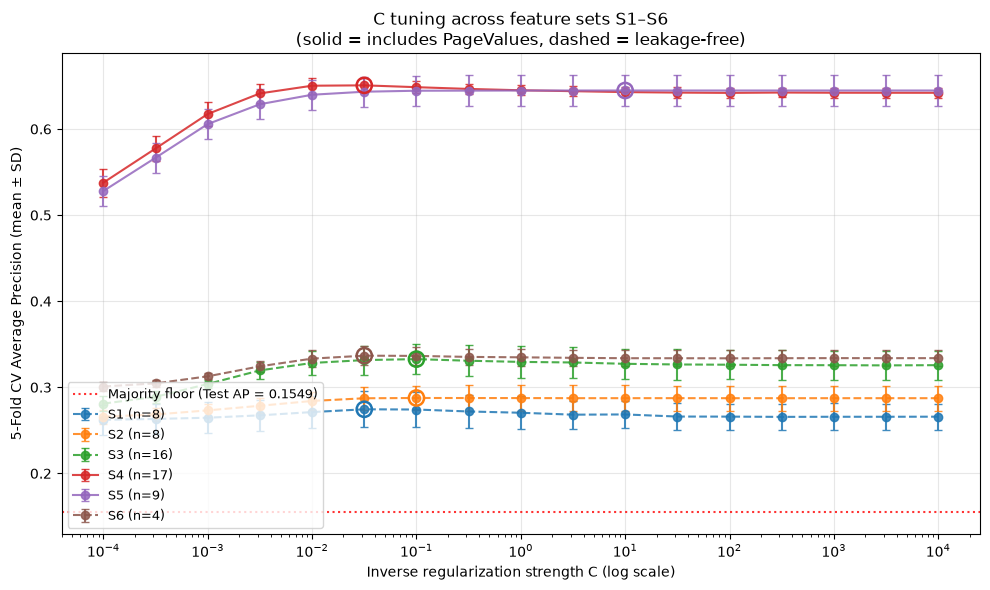

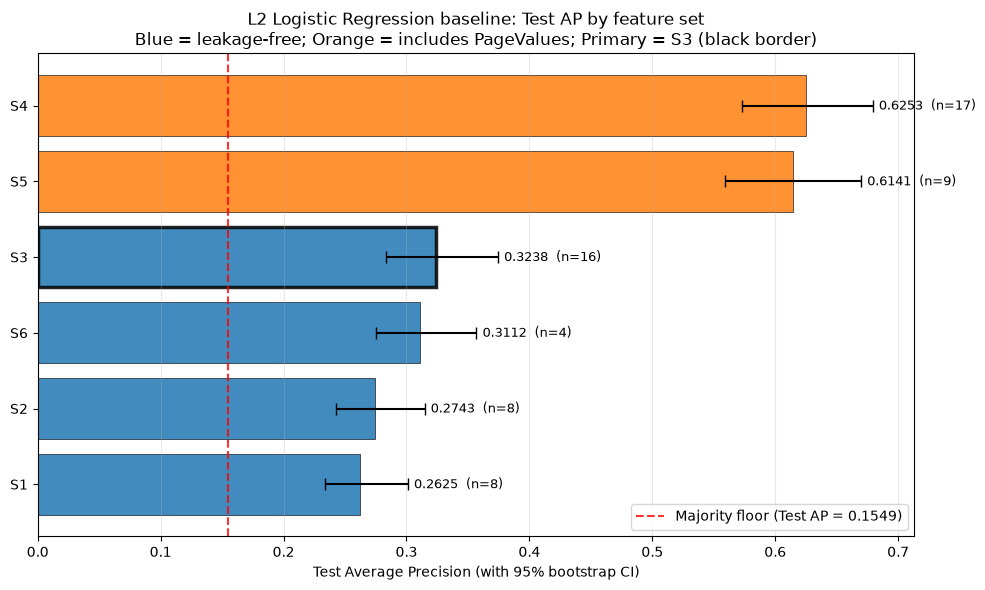

Figures saved to:
  C:\Users\ysd9451\Desktop\5420\pro\cv_ap_vs_C_by_set.png
  C:\Users\ysd9451\Desktop\5420\pro\baseline.png  <-- submit this with baseline.txt


In [10]:
# ----- Figure A: CV AP vs C for S1-S6 -----
fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.get_cmap("tab10")
for i, (s_name, info) in enumerate(set_tuning.items()):
    tune_df = info["cv_table"]
    color = cmap(i)
    linestyle = "-" if info["includes_pagevalues"] else "--"
    ax.errorbar(tune_df["C"], tune_df["Mean CV AP"], yerr=tune_df["Std CV AP"],
                marker="o", capsize=3, color=color, linestyle=linestyle,
                label=f"{s_name} (n={info['n_features']})", alpha=0.85)
    ax.scatter([info["best_C"]], [info["best_cv_mean"]],
               s=120, facecolors="none", edgecolors=color, linewidth=1.8, zorder=5)
ax.axhline(majority_ap, color="red", linestyle=":", alpha=0.8,
           label=f"Majority floor (Test AP = {majority_ap:.4f})")
ax.set_xscale("log")
ax.set_xlabel("Inverse regularization strength C (log scale)")
ax.set_ylabel("5-Fold CV Average Precision (mean ± SD)")
ax.set_title("C tuning across feature sets S1–S6\n"
             "(solid = includes PageValues, dashed = leakage-free)")
ax.legend(loc="lower left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
figA_path = Path("cv_ap_vs_C_by_set.png")
fig.savefig(figA_path, dpi=180, bbox_inches="tight")
plt.show()

# ----- Figure B: Test AP + bootstrap CI (= baseline.png) -----
PRIMARY_KEY = "S3"
plot_df = test_results_df[test_results_df["Feature Set"] != "Majority-Class Floor"].copy()
plot_df = plot_df.sort_values("Test AP", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6))
positions = np.arange(len(plot_df))
colors = ["#ff7f0e" if pv else "#1f77b4" for pv in plot_df["PageValues"]]
err_lower = plot_df["Test AP"] - plot_df["Test AP CI low"]
err_upper = plot_df["Test AP CI high"] - plot_df["Test AP"]
bars = ax.barh(positions, plot_df["Test AP"], xerr=[err_lower, err_upper],
               color=colors, alpha=0.85, capsize=4,
               edgecolor="black", linewidth=0.5)

# Highlight the primary baseline (S3) with a thicker border.
for pos, name in enumerate(plot_df["Feature Set"]):
    if name == PRIMARY_KEY:
        bars[pos].set_edgecolor("black")
        bars[pos].set_linewidth(2.5)

ax.axvline(majority_ap, color="red", linestyle="--", alpha=0.8,
           label=f"Majority floor (Test AP = {majority_ap:.4f})")

# Add Test AP + n_features labels next to each bar.
for pos, row in plot_df.iterrows():
    label = f"{row['Test AP']:.4f}  (n={int(row['# Features'])})"
    ax.text(row["Test AP CI high"] + 0.005, pos, label,
            va="center", fontsize=9)

ax.set_yticks(positions)
ax.set_yticklabels(plot_df["Feature Set"])
ax.set_xlabel("Test Average Precision (with 95% bootstrap CI)")
ax.set_title("L2 Logistic Regression baseline: Test AP by feature set\n"
             "Blue = leakage-free; Orange = includes PageValues; "
             "Primary = S3 (black border)")
ax.legend(loc="lower right")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
figB_path = Path("baseline.png")
fig.savefig(figB_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"Figures saved to:")
print(f"  {figA_path.resolve()}")
print(f"  {figB_path.resolve()}  <-- submit this with baseline.txt")

## 10. Summary tables — numbers to copy into `baseline.txt`

1. **Primary baseline (S3)**: the 9 numbers that go verbatim into `baseline.txt`'s `## Result` section.
2. **PageValues leakage comparison**: S3 vs S4 Test AP gap for `## Issues found`.
3. **Full S1–S6 + floor** comparison.

In [11]:
# ----- Table 1: Primary baseline (S3) -----
primary_row = test_results_df[test_results_df["Feature Set"] == "S3"].iloc[0]
primary_summary = pd.DataFrame({
    "Field": [
        "Primary feature set",
        "# Features",
        "Best C",
        "CV AP (mean)",
        "CV AP (fold SD)",
        "Test AP (point estimate)",
        "Test AP bootstrap 95% CI low",
        "Test AP bootstrap 95% CI high",
        "Majority-class floor (Test AP)",
        "Test-set size",
        "Test positive rate",
    ],
    "Value": [
        "S3 (session + browsing, no PageValues)",
        int(primary_row["# Features"]),
        f"{primary_row['Best C']:g}",
        f"{primary_row['CV AP (mean)']:.4f}",
        f"{primary_row['CV AP (fold SD)']:.4f}",
        f"{primary_row['Test AP']:.4f}",
        f"{primary_row['Test AP CI low']:.4f}",
        f"{primary_row['Test AP CI high']:.4f}",
        f"{majority_ap:.4f}",
        f"{len(y_test_int)}",
        f"{float(y_test_int.mean()):.4f}",
    ]
})
print("=== Table 1: Primary baseline summary (copy into baseline.txt ## Result) ===")
print(primary_summary.to_string(index=False))

# ----- Table 2: PageValues leakage comparison (S3 vs S4) -----
s3_ap = float(test_results_df[test_results_df["Feature Set"] == "S3"]["Test AP"].iloc[0])
s4_ap = float(test_results_df[test_results_df["Feature Set"] == "S4"]["Test AP"].iloc[0])
leakage_table = pd.DataFrame({
    "Model":   ["S3 (no PageValues, primary)", "S4 (with PageValues)", "Difference (S4 - S3)"],
    "Test AP": [f"{s3_ap:.4f}", f"{s4_ap:.4f}", f"{s4_ap - s3_ap:+.4f}"],
})
print()
print("=== Table 2: PageValues leakage comparison (for baseline.txt ## Issues found) ===")
print(leakage_table.to_string(index=False))

# ----- Table 3: Full S1-S6 + floor comparison -----
print()
print("=== Table 3: Full comparison across feature sets S1-S6 + majority floor ===")
print(test_results_df.sort_values("Test AP", ascending=False).to_string(index=False))

=== Table 1: Primary baseline summary (copy into baseline.txt ## Result) ===
                         Field                                  Value
           Primary feature set S3 (session + browsing, no PageValues)
                    # Features                                     16
                        Best C                                    0.1
                  CV AP (mean)                                 0.3327
               CV AP (fold SD)                                 0.0177
      Test AP (point estimate)                                 0.3238
  Test AP bootstrap 95% CI low                                 0.2831
 Test AP bootstrap 95% CI high                                 0.3744
Majority-class floor (Test AP)                                 0.1549
                 Test-set size                                   2466
            Test positive rate                                 0.1549

=== Table 2: PageValues leakage comparison (for baseline.txt ## Issues found) ===
